# Part 2 · Circuits / Digital Quantum Computing

In Part 1, we constructed quantum states and inspected them. Now we **operate on them**. The **digital**, or **gate-based**, model builds programs as circuits: ordered sequences of operations called **gates**. We will assemble these circuits, run them on QiliSDK's `QiliSim` simulator, and measure the results.

The other model, **analog**, has no gates. The qubits' energy, described by a **Hamiltonian**, changes smoothly over time, and we measure where the system ends up. Quantum annealing works this way, and so do Qilimanjaro's analog processors. In annealing, a starting Hamiltonian fades out while one that encodes the problem fades in; the two curves in the figure below show this. QiliSDK programs both; this tutorial stays digital.

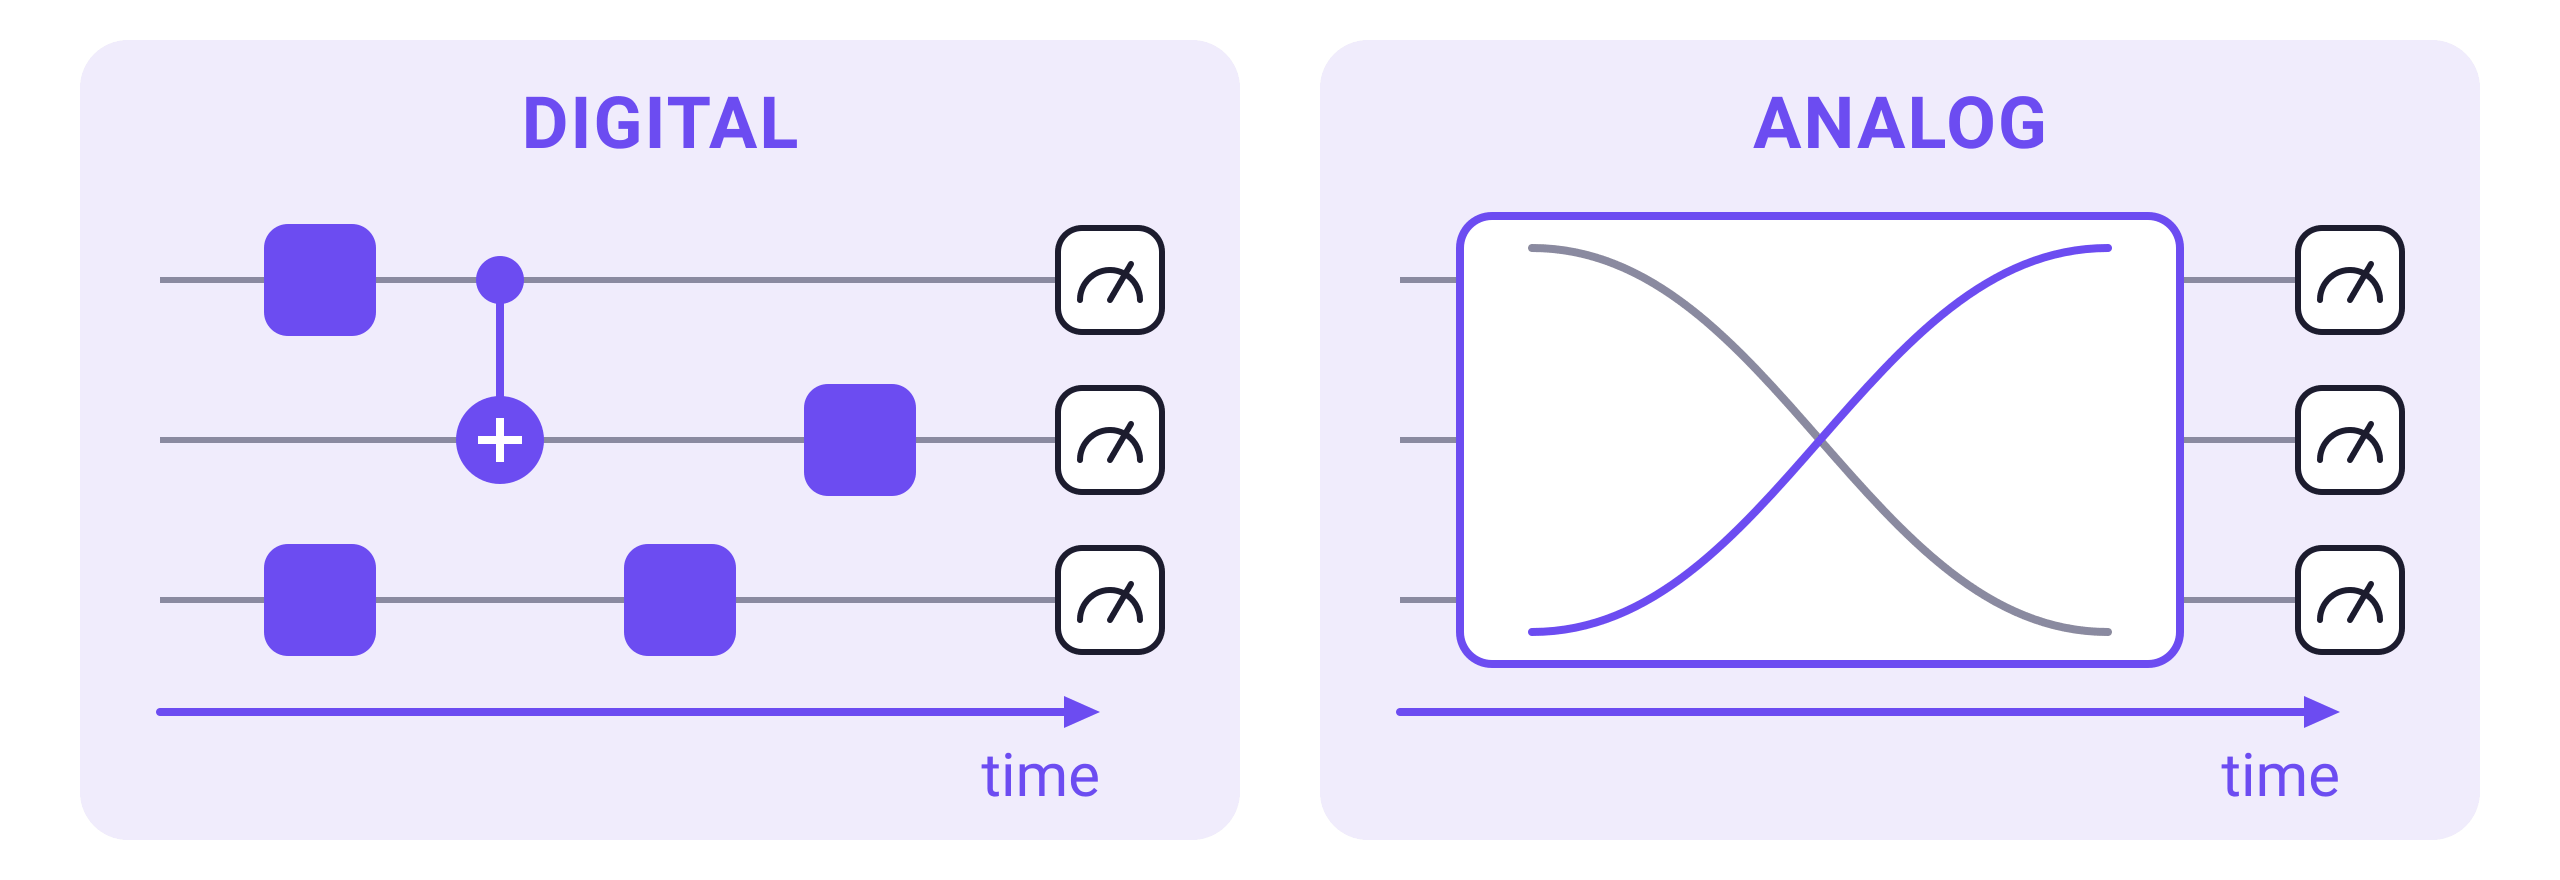

The digital model is behind Shor's factoring algorithm, Grover's search algorithm, and quantum simulations of molecules. Shor's algorithm factors integers and computes discrete logarithms far faster than any known classical method, so a large error-corrected quantum computer could break RSA and elliptic-curve cryptography. No such machine exists yet, but encrypted traffic recorded today could be decrypted later, so the move to post-quantum cryptography has already started; NIST published the first standards in 2024. Grover's algorithm gives a smaller, quadratic speedup: it searches $N$ possibilities in about $\sqrt N$ steps.

We will start with smaller examples: generating a random bit, turning those bits into dice rolls, and preparing a shared bit for three parties. These fit on a laptop and let us examine how the gates produce each result. You will:

- build a `Circuit` and interpret its gates as matrices;
- run circuits and compare sampled counts with probabilities calculated from the state;
- observe interference and prepare entangled states;
- simulate a fair coin, a dice roller, and a random bit shared by three qubits;
- compile a circuit for a chip's available gates and wiring, then count the extra operations required.

Run the cells in order, starting with the installation cell below. The examples use QiliSDK 0.3.0; the installation cell leaves any existing version unchanged, so check the version it prints.

### The execution pattern

A **Functional** describes what to run, a **Backend** is the simulator that runs it, and a **Readout** specifies the result to collect. They meet in this call:

$$\texttt{Backend.execute(functional, readout)} \;\longrightarrow\; \texttt{Result}$$

This separation lets a computation use different compatible backends. Availability of functionals and readouts depends on the backend; for example, a hardware quantum processing unit (**QPU**) cannot expose its exact state vector as a simulator can.

Real hardware is reached differently. `SpeQtrum` is the client for Qilimanjaro's cloud service, not a backend. After `pip install "qilisdk[speqtrum]"`, you log in with an account and API key and `submit` the same `DigitalPropagation` and `Readout` to a device listed by `list_devices()`. You then wait for the job and read its result with the same methods as a `QiliSim` result.

In [ ]:
# Run me first: install QiliSDK if missing, then display its version.
try:
    import qilisdk
except ImportError:
    import sys
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "qilisdk==0.3.0"], check=True)
    # Colab: if this import fails, restart the session and rerun from the top.
    import qilisdk
print(qilisdk.__version__)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 2.1 · Gates and circuits

The examples build on Part 1's state vectors and measurement rule. As a reminder, $|0\rangle$ and $|1\rangle$ are the computational basis states; a normalized vector of complex amplitudes describes a pure state. Measuring in that basis gives each outcome with probability equal to the squared magnitude of its amplitude. We will use $|+\rangle = (|0\rangle + |1\rangle)/\sqrt2$ and $|-\rangle = (|0\rangle - |1\rangle)/\sqrt2$ throughout.

A quantum **gate** changes a state. A gate on $n$ qubits is represented by a $2^n \times 2^n$ **unitary matrix** $U$, meaning $U^\dagger U = I$. Here $I$ is the identity matrix and $\dagger$ denotes the conjugate transpose, `U.conj().T` in NumPy. Unitarity has two consequences:

- gates are **reversible**: the inverse of $U$ is $U^\dagger$, while the output of a classical AND or OR does not determine its inputs;
- gates **preserve the norm** of the state, so its measurement probabilities continue to sum to 1.

For an input state $|\psi\rangle$, applying the gate produces $|\psi'\rangle = U\,|\psi\rangle$. `QTensor` represents both state vectors and operator matrices. Use `@` for this matrix–vector multiplication. The `*` operator performs scalar or element-wise multiplication and does not apply an operator to a state; with a `QTensor` operator it silently returns a wrong vector instead of raising an error.

The main gates used below are:

- **Hadamard** $H = \tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ creates an equal superposition from $|0\rangle$: $H|0\rangle = \tfrac{1}{\sqrt2}\,(|0\rangle + |1\rangle)$, also written $|+\rangle$.
- **Pauli-$X$** $= \begin{pmatrix}0&1\\1&0\end{pmatrix}$ flips the computational basis states: $X|0\rangle = |1\rangle$ and $X|1\rangle = |0\rangle$. Together with $Y$ and $Z$, introduced below, it forms the set of three Pauli gates.
- **Rotations** $R_X(\theta)$, $R_Y(\theta)$, and $R_Z(\phi)$ turn a qubit's state about the corresponding axis of the Bloch sphere, the geometric representation introduced in Part 1. The angles $\theta$ and $\phi$ are in radians and are passed as Python floats. **Variational** quantum algorithms tune such angles with a classical optimizer, much as training adjusts a neural network's weights. For example, $R_X(\theta) = e^{-i\theta X/2}$, where $i$ is the imaginary unit and the exponential is a **matrix exponential**, as computed by `scipy.linalg.expm`.
- **CNOT** (controlled-NOT) acts on two qubits: it flips the **target** when the **control** is 1. On basis states, this is `target ^= control`, an exclusive OR. The gate also acts on superpositions, applying the rule to each basis component.

CNOT's truth table writes the control first and the target second:

| in (control, target) | out | why |
|---|---|---|
| $\lvert 00\rangle$ | $\lvert 00\rangle$ | control is 0: do nothing |
| $\lvert 01\rangle$ | $\lvert 01\rangle$ | control is 0: do nothing |
| $\lvert 10\rangle$ | $\lvert 11\rangle$ | control is 1: flip the target |
| $\lvert 11\rangle$ | $\lvert 10\rangle$ | control is 1: flip the target |

CNOT can create entanglement, for example when its control is in superposition and its target is $|0\rangle$, as section 2.4 demonstrates.

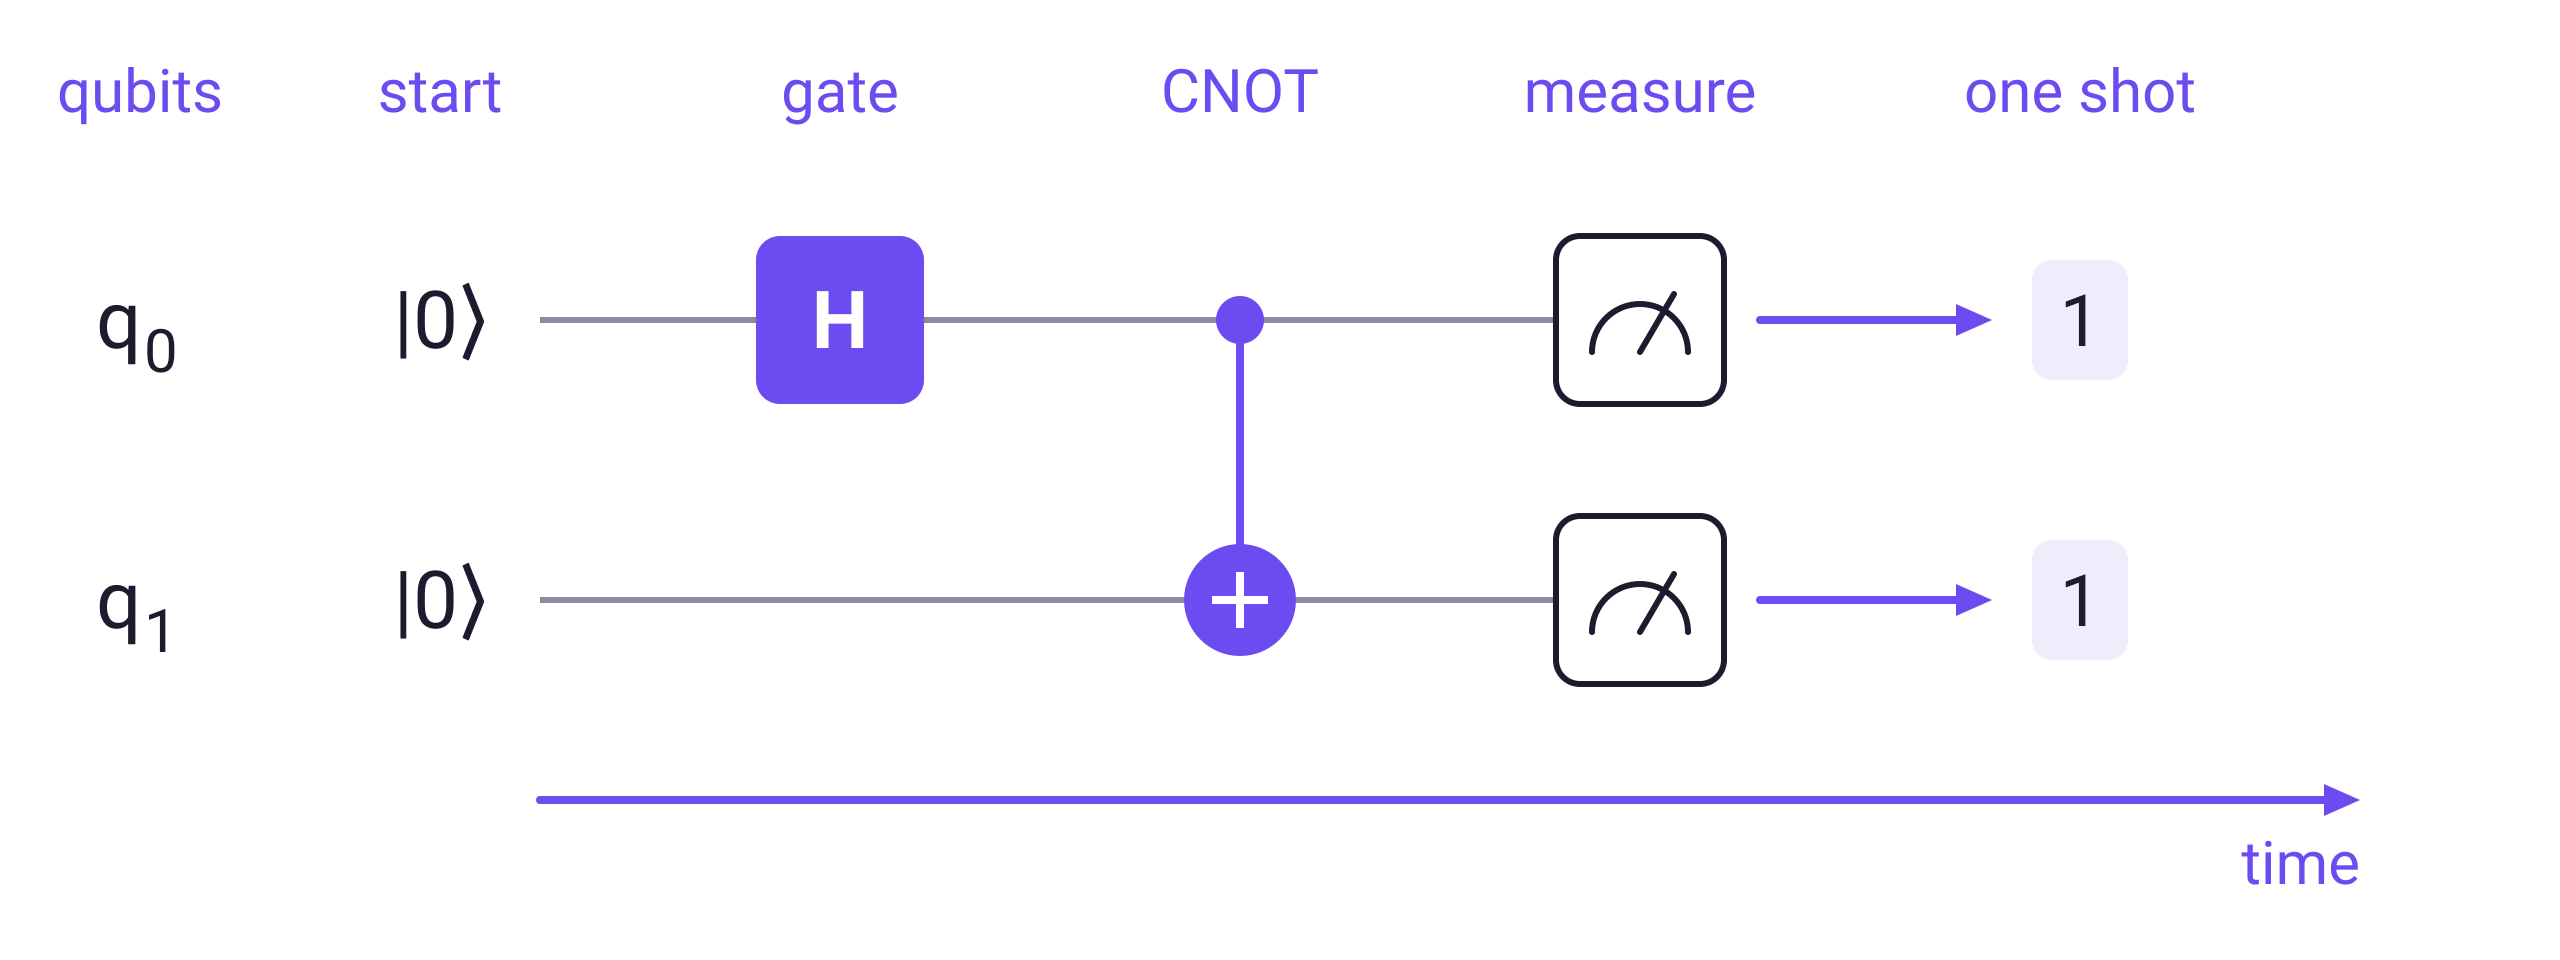

Circuit diagrams read like a timeline. Each horizontal wire is a qubit, with qubit 0 on top, and time runs left to right. Boxes are gates, a dot joined to ⊕ is a CNOT with the dot on its control, and a meter is a measurement that turns its qubit into one bit per shot. `circuit.draw()` uses the same conventions.

A **`Circuit`** stores operations on qubits indexed $0, 1, 2, \dots$. Add them with `.add(...)` in the order they should run. With no initial state supplied, execution starts from $|0\cdots0\rangle$. Applying gate $A$ and then $B$ computes $B\,A\,|\psi\rangle$: matrix products act from right to left, like nested function calls. In a drawing, $A$ sits to the left of $B$.

The first circuit applies $X$ to one qubit and then measures it with `M`. A **shot** is one preparation and measurement of the circuit. Since $X$ changes the initial $|0\rangle$ to $|1\rangle$, every shot should return `'1'`. We will execute this circuit in section 2.2.

In [ ]:
from qilisdk.digital import Circuit, H, X, Y, Z, I, CNOT, M, RX, RY, RZ

# One qubit, starting in |0>: flip it with X, then measure it
quantum_not = Circuit(1)
quantum_not.add(X(0))
quantum_not.add(M(0))

print(quantum_not)
quantum_not.draw()

### Gate matrices

Each unitary gate object exposes its matrix through **`.matrix`**. The next cell prints eight single-qubit matrices:

- the **identity** $I$, which leaves the state unchanged, and the Pauli gates $X$ (bit flip), $Y$ (bit and phase flip), and $Z$ (phase flip);
- the **Hadamard** $H$, which exchanges computational basis states with the plus and minus states;
- the rotation gates, defined by matrix exponentials:
  $$R_X(\theta)=e^{-i\theta X/2},\qquad R_Y(\theta)=e^{-i\theta Y/2},\qquad R_Z(\phi)=e^{-i\phi Z/2}.$$

The angles $\theta$ and $\phi$ are measured in radians. `RX` and `RY` use the keyword `theta=`, while `RZ` uses `phi=`. The example uses $\pi/2$ for all three rotations.

In [ ]:
# The rotations use pi/2 as a representative angle
gates = [I(0), X(0), Y(0), Z(0), H(0),
         RX(0, theta=np.pi / 2), RY(0, theta=np.pi / 2), RZ(0, phi=np.pi / 2)]

for gate in gates:
    print(gate)
    print(gate.matrix)

### How gates transform the four reference states

The table shows how the five fixed gates act on $|0\rangle$, $|1\rangle$, $|+\rangle$, and $|-\rangle$. A factor such as $-1$ or $i$ multiplying the whole output ket is a **global phase** and does not change the physical state. A **relative phase** changes the relationship between amplitudes within a state and can affect later interference.

The poles are $|0\rangle$ and $|1\rangle$ on the Bloch sphere; $|+\rangle$ and $|-\rangle$ are the two points on its $X$ axis.

| gate | $\lvert 0\rangle$ | $\lvert 1\rangle$ | $\lvert +\rangle$ | $\lvert -\rangle$ | effect on these states |
|---|---|---|---|---|---|
| $I$ | $\lvert 0\rangle$ | $\lvert 1\rangle$ | $\lvert +\rangle$ | $\lvert -\rangle$ | **identity**: leaves every state unchanged |
| $X$ | $\lvert 1\rangle$ | $\lvert 0\rangle$ | $\lvert +\rangle$ | $-\lvert -\rangle$ | **bit flip**: exchanges the poles; preserves the $\pm X$ states up to global phase |
| $Y$ | $i\lvert 1\rangle$ | $-i\lvert 0\rangle$ | $-i\lvert -\rangle$ | $i\lvert +\rangle$ | **bit and phase flip**: exchanges both pairs, with phase factors |
| $Z$ | $\lvert 0\rangle$ | $-\lvert 1\rangle$ | $\lvert -\rangle$ | $\lvert +\rangle$ | **phase flip**: preserves the poles; exchanges the $\pm X$ states |
| $H$ | $\lvert +\rangle$ | $\lvert -\rangle$ | $\lvert 0\rangle$ | $\lvert 1\rangle$ | **basis change**: exchanges the $Z$ and $X$ bases |

Rotation gates can produce states outside these four, so the code prints output amplitudes instead of state labels. It checks the table and applies the rotations at $\theta = \pi/2$. Compare phase factors on the whole vector with phase differences between its entries. For example, $R_X$ turns $|+\rangle$ into `[0.5-0.5j 0.5-0.5j]`, which is $|+\rangle$ multiplied by $e^{-i\pi/4}$. That factor is a global phase, so the state is unchanged, as the Bloch spheres in the next section show.

In [ ]:
# State tools live in qilisdk.core, gates in qilisdk.digital
from qilisdk.core import QTensor, ket

states = {
    "|0>": ket(0),
    "|1>": ket(1),
    "|+>": QTensor.uniform(1),
    "|->": (ket(0) - ket(1)).normalized(),
}

# QTensor(gate.matrix) turns a gate into an operator to apply with @, and .dense().ravel()
# prints the result's amplitudes on one line. Read tiny values such as 1.11e-16 as 0:
# they are floating-point rounding.
for gate in gates:
    for name, state in states.items():
        print(gate.name, name, (QTensor(gate.matrix) @ state).dense().ravel())

### Gates on the Bloch sphere

On the Bloch sphere, a pure single-qubit state is a point: $|0\rangle$ is at the north pole, $|1\rangle$ at the south pole, and $|+\rangle$ and $|-\rangle$ at opposite ends of the equator's $X$ axis. A single-qubit unitary gate rotates this sphere:

- $X$, $Y$, and $Z$ rotate by **180°** about their respective axes;
- $H$ rotates by 180° about the diagonal axis halfway between $X$ and $Z$;
- $R_X(\theta)$, $R_Y(\theta)$, and $R_Z(\phi)$ rotate by their specified angles about the corresponding axes;
- $I$ leaves every point unchanged.

The next cell applies each gate first to $|0\rangle$, then to $|+\rangle$. A state on the rotation axis stays at the same point: $Z$ and $R_Z$ leave $|0\rangle$ fixed, while $X$ and $R_X$ leave $|+\rangle$ fixed. From $|0\rangle$, both $X$ and $Y$ reach the south pole; their output vectors differ only by a global phase, which the sphere does not display.

In [ ]:
from qilisdk.utils.visualization import QTensorStyle

# Each gate applied to |0> on the pole, then to |+> on the equator, at a smaller dpi
for start, state in [("|0>", ket(0)), ("|+>", QTensor.uniform(1))]:
    for gate in gates:
        after = QTensor(gate.matrix) @ state
        after.draw(style=QTensorStyle(title=f"{gate.name} applied to {start}", dpi=100))

### Interference: applying $H$ twice

The Hadamard gate is its own inverse: $H\,H = I$. Applying it to $|0\rangle$ gives $|+\rangle$; applying it again returns $|0\rangle$. This is **interference**: in the second matrix multiplication, contributions to the $|1\rangle$ amplitude have opposite signs and cancel, while contributions to $|0\rangle$ add. The minus sign comes from the bottom-right entry of $H$. A classical coin randomized twice stays 50/50, but the qubit returns to $0$ every time. Quantum algorithms are built on this kind of cancellation.

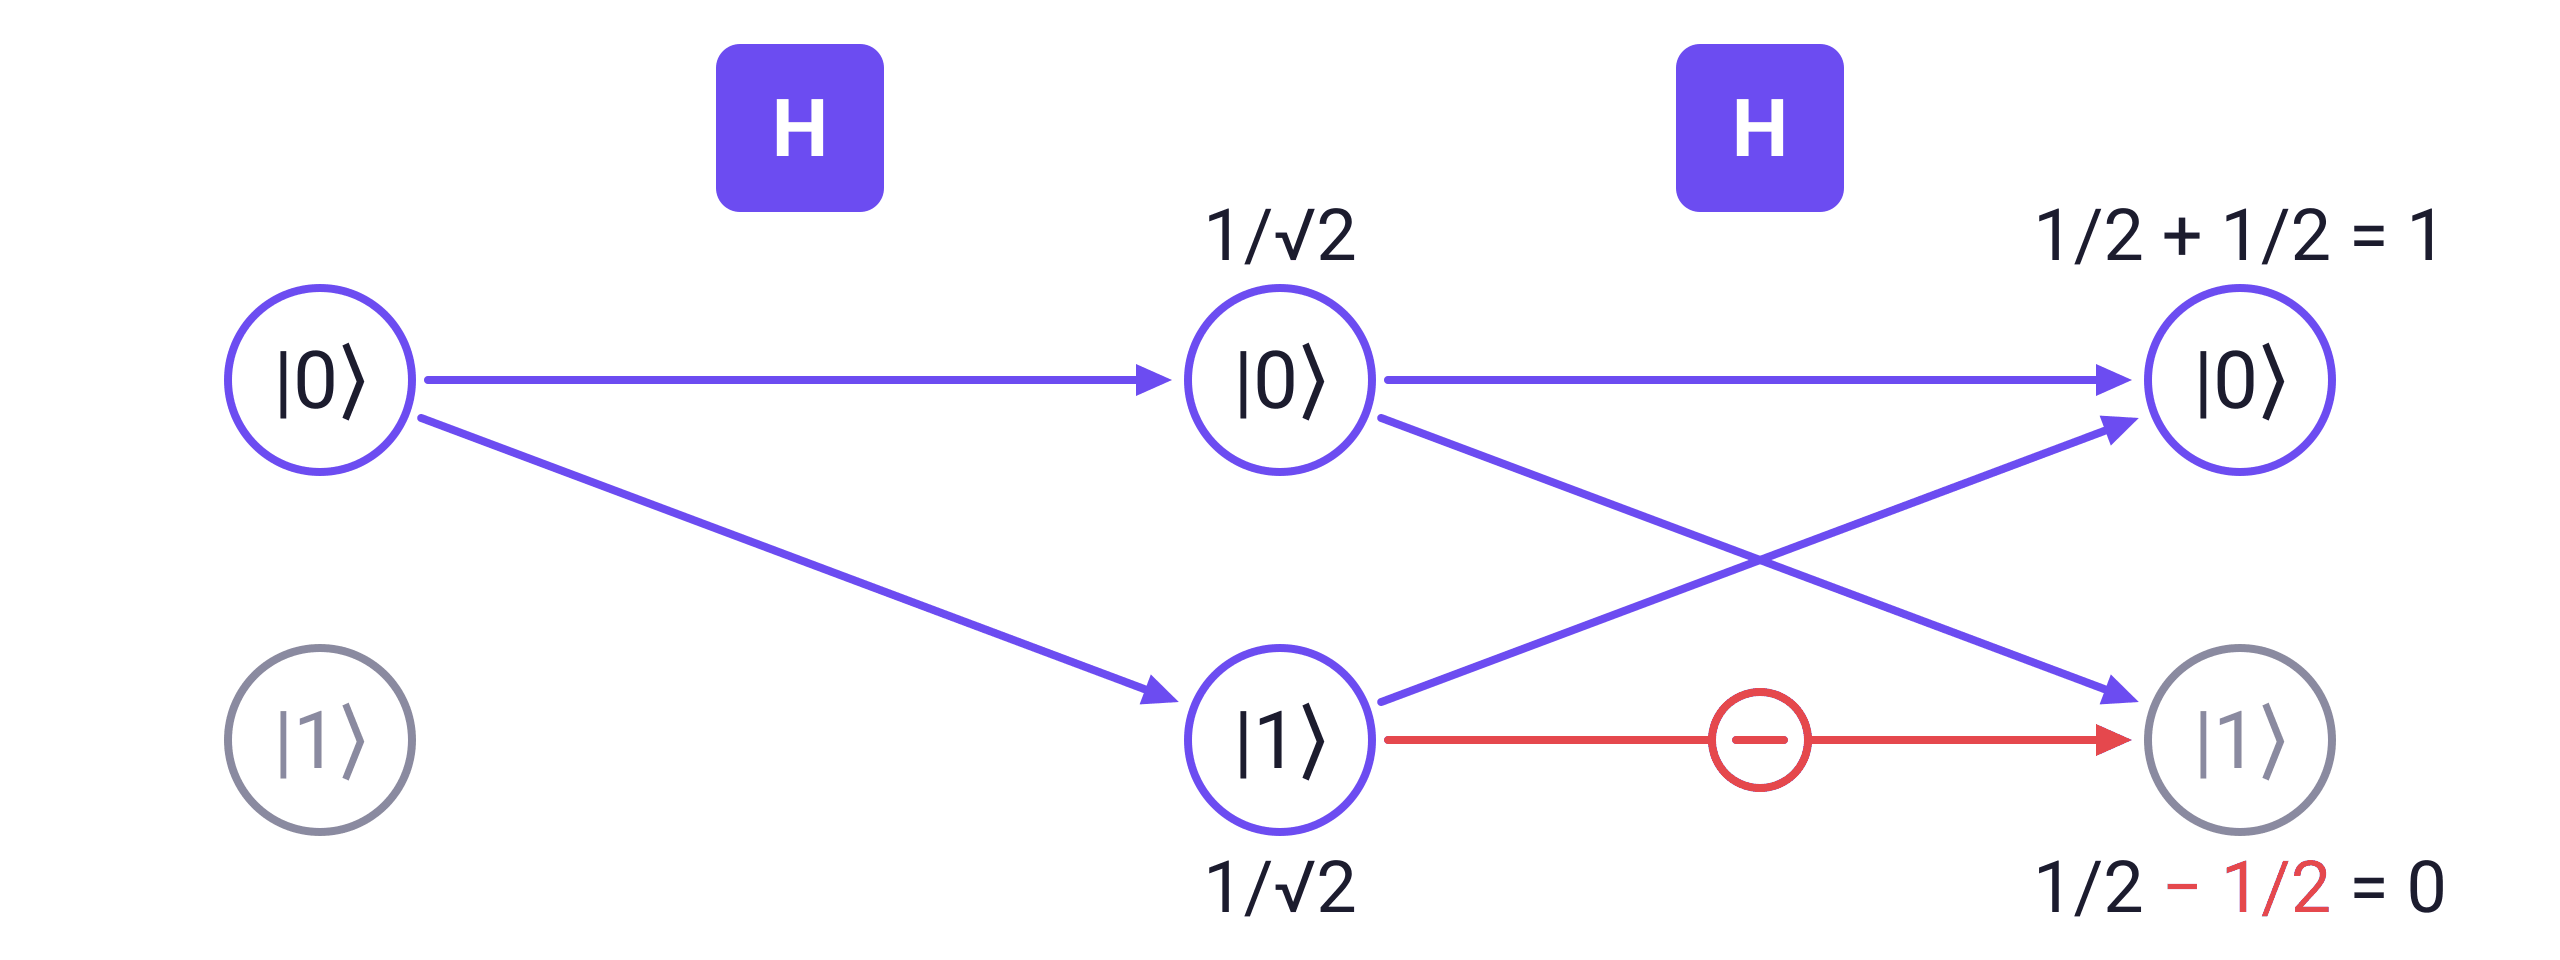

There is no measurement between the two gates, so the intermediate state retains its relative phases. Measuring after the first gate would change that state and prevent the same cancellation. The next cell applies the two matrices explicitly and prints the intermediate and final amplitudes.

In [ ]:
# The Hadamard matrix as a QTensor operator
Hm = QTensor(H(0).matrix)

# H|0> = |+>, an equal superposition
step1 = Hm @ ket(0)
print(step1)

# H(H|0>): the two paths to |1> cancel, leaving |0>
step2 = Hm @ step1
print(step2)

**Measurement (`M`) is not unitary.** Measuring all qubits in the computational basis produces a classical bitstring with probabilities given by the Born rule and collapses the state to the corresponding basis state. A circuit containing measurement therefore cannot be described by a single unitary matrix. The interference in the previous example must happen before measurement.

QiliSDK provides the single-qubit gates `I, H, X, Y, Z, S, T`, parameterized rotations `RX, RY, RZ`, general gates `U1, U2, U3`, and two-qubit gates `CNOT, CZ, SWAP`. `CZ` is a controlled phase flip: it multiplies the amplitude of $|11\rangle$ by $-1$ and leaves the others alone. A CNOT equals a CZ with an $H$ on each side of the target, which is why chips that offer only CZ can still run CNOTs. `SWAP` exchanges two qubit states. Gate combinators construct a controlled version (`Controlled`), a conjugate transpose (`Adjoint`), or a matrix exponential (`Exponential`). Later examples introduce the additional gates they use.

Rotation angles are **keyword-only**: write `RX(0, theta=1.57)`. Passing the angle as `RX(0, 1.57)` raises a `TypeError`.

For a circuit without measurement, `to_matrix()` returns the full $2^n \times 2^n$ unitary, where $n$ is the number of qubits. The next cell draws a one-qubit circuit and checks that its matrix has shape `(2, 2)`.

In [ ]:
u = Circuit(1)
u.add(H(0))
# Rotation angles are passed by keyword
u.add(RX(0, theta=np.pi / 2))
u.draw()

# One qubit: a 2**1 x 2**1 matrix
print(u.to_matrix().shape)

## 2.2 · Running a circuit and reading results

So far we have built circuits and applied individual gate matrices by hand. To run a whole circuit, use `Backend.execute(functional, readout)`, choosing what to run, where to run it, and which results to collect:

1. **Functional:** wrap the circuit in `DigitalPropagation`. With no initial state supplied, it starts from $|0\cdots0\rangle$ and applies the circuit's operations. A bare `Circuit` cannot be passed directly for execution.
2. **Backend:** use `QiliSim`, the C++ simulator included with QiliSDK. For these ideal circuits, it stores a state vector and applies the gates to its amplitudes. The $2^n$ storage requirement doubles with each additional qubit.
3. **Readout:** choose what to collect. `Readout().with_sampling(...)` requests measurement counts. `with_expectation(...)` requests the mean of an **observable**, a measurable quantity such as energy. `with_state_tomography()` returns state information calculated by the simulator.

Your Python code describes the job; the backend runs it. With sampling, a QPU repeats three steps `nshots` times: prepare the state, apply the gates, measure. Then it returns the counts. QiliSim instead computes the final state once and draws `nshots` samples from it, which gives the same statistics when every measurement comes at the end.

First, execute the NOT circuit from section 2.1. Its final state before measurement is $X|0\rangle = |1\rangle$, so all 1000 shots should return `'1'`.

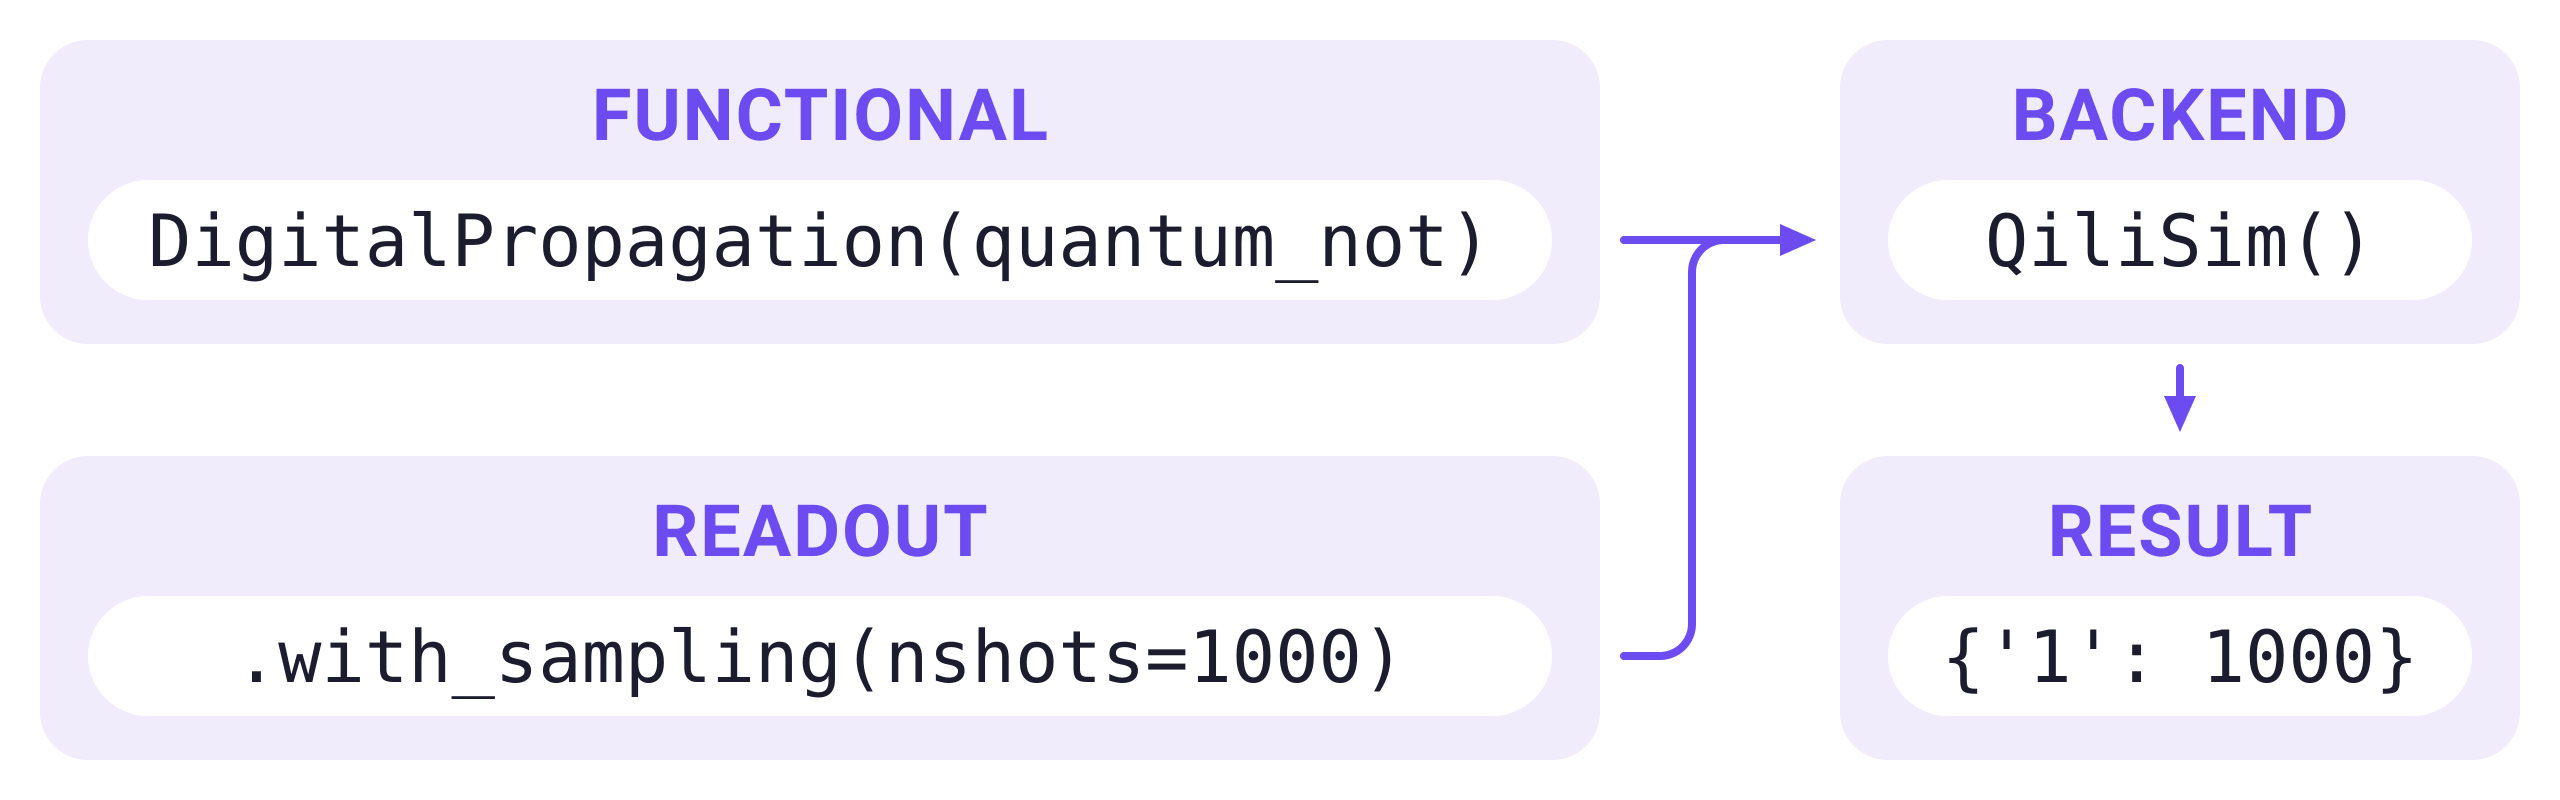

In [ ]:
from qilisdk.functionals import DigitalPropagation
from qilisdk.backends import QiliSim
from qilisdk.readout import Readout

functional = DigitalPropagation(quantum_not)
readout = Readout().with_sampling(nshots=1000)
result = QiliSim().execute(functional, readout)

# Every shot gives '1', like a classical NOT
print(result.get_samples())

All 1000 shots return `'1'`. To get a distribution of outcomes, the next circuit uses $R_X$ to prepare a superposition with probabilities $0.25$ and $0.75$. $R_X(\theta)$ tips the state $\theta$ radians away from the north pole of the Bloch sphere, so $P(1) = \sin^2(\theta/2)$; with $\theta = 2\pi/3$ (120°) that is $0.75$, the loaded coin from Exercise 1.1. $R_X$ also puts a phase of $-i$ on the $|1\rangle$ amplitude, which the probabilities do not show; $R_Y(2\pi/3)$ would prepare exactly the Exercise 1.1 state.

**Sampling** draws `nshots` outcomes from that distribution. Each shot represents a fresh preparation and measurement; QiliSim uses pseudorandom sampling to model the measurements. The resulting relative frequencies vary between runs. This variation is called **shot noise**. For independent samples, the typical uncertainty in an estimated probability decreases as $1/\sqrt{\text{nshots}}$, so gaining one decimal digit of precision requires about 100 times as many shots. With 1000 shots and $p = 0.75$, the standard deviation of the count is $\sqrt{\text{nshots}\cdot p\,(1-p)} \approx 14$, so the count of `'1'` typically lands within about 14 of 750.

In [ ]:
# Rotate partway: P(0) = 0.25, P(1) = 0.75
biased = Circuit(1)
biased.add(RX(0, theta=2 * np.pi / 3))
biased.add(M(0))

biased_result = QiliSim().execute(DigitalPropagation(biased), Readout().with_sampling(nshots=1000))
# About 250 '0' and 750 '1'
print(biased_result.get_samples())
# The same counts as frequencies
print(biased_result.get_probabilities())

Sampled frequencies fluctuate around the underlying probabilities. A simulator can also calculate those probabilities directly from its stored state vector, without shot noise. QiliSDK exposes this through `with_state_tomography()`.

On hardware, **state tomography** means estimating a state from repeated measurements in different bases. For $n$ qubits that takes $3^n$ combinations of bases with many shots each, which is practical only for a handful of qubits. QiliSim already stores the state, and `with_state_tomography()` returns it. We call this readout **exact**, allowing for floating-point rounding. By default QiliSim records `M` without collapsing its stored state, so this is the state just before measurement.

Use the exact readout to check the ideal circuit's probabilities and sampling to study the variation expected from a finite number of measurements.

In [ ]:
biased_exact = QiliSim().execute(DigitalPropagation(biased), Readout().with_state_tomography())
# 0.25 and 0.75, up to floating-point rounding
print(biased_exact.get_probabilities())

The histogram shows the sampled counts. For an outcome with exact probability $p$, the expected count is $\text{nshots} \times p$, here 250 and 750. The bars differ from those numbers because of shot noise.

In [ ]:
counts = biased_result.get_samples()
plt.bar(counts.keys(), counts.values())
plt.show()

## 2.3 · A fair quantum coin

Random numbers are used in cryptography, lotteries, scientific simulation, and online gaming. A pseudorandom generator produces them with a deterministic algorithm: given the same initial seed, it repeats the same sequence. A quantum random number generator (**QRNG**) instead uses the unpredictability of physical quantum measurements. Python's `secrets` module also draws on physical noise collected by the operating system, but a QRNG's unpredictability follows directly from quantum mechanics.

The circuit below demonstrates the measurement principle with one qubit. Preparing $|+\rangle$ and measuring it gives a fair coin because the Born rule assigns probability $0.5$ to each outcome. Here QiliSim samples that distribution pseudorandomly to simulate the measurements.

Build and check the circuit in three steps:

1. Apply $H$ to the initial $|0\rangle$ to prepare $|+\rangle$.
2. Request the exact readout to check that the ideal circuit assigns probability $0.5$ to each outcome.
3. Sample 1000 shots and compare the counts with the expected equal split.

The exact readout checks the probabilities of our ideal circuit. A physical random number generator also needs checks on its preparation and measurement. To generate numbers in a larger range, we can use more qubits and discard unwanted outcomes; the dice exercise builds on this idea.

QiliSDK can also send circuits to Qilimanjaro's quantum processors through the optional `SpeQtrum` client. It needs a SpeQtrum account, and the device decides which gates and readouts it accepts. Section 2.5 shows what compiling a circuit for a chip involves.

In [ ]:
# H turns |0> into |+>, an equal superposition of 0 and 1; then measure
coin = Circuit(1)
coin.add(H(0))
coin.add(M(0))

# The ideal circuit gives each outcome probability 0.5
coin_exact = QiliSim().execute(DigitalPropagation(coin), Readout().with_state_tomography())
print(coin_exact.get_probabilities())

# 1000 flips, sampled pseudorandomly by QiliSim
flips = QiliSim().execute(DigitalPropagation(coin), Readout().with_sampling(nshots=1000))
print(flips.get_samples())

### 🧩 Exercise 2.1: build a quantum dice roller

Use several qubits to produce uniformly distributed bitstrings, then convert them into the outcomes of a **d6**, a six-sided die. The number of raw bitstrings is a power of two, so you will need to discard some outcomes to keep the die fair.

1. Choose the smallest number of qubits $n$ for which $2^n \geq 6$.
2. Apply an $H$ to each qubit and measure all of them.
3. Check the exact readout: each raw outcome should have probability $1/2^n$, allowing for floating-point rounding.
4. Sample 4000 shots. Convert each bitstring to a face value with `int(bitstring, 2) + 1` and keep only values up to 6. Discarding surplus outcomes is **rejection sampling**, also used by Python's `random.randrange`. It avoids the bias that would result from mapping eight equally likely outcomes onto six faces using modulo arithmetic. Expect to keep $6/8 = 75\%$ of the shots.
5. Print the keep rate and the count for each face. Each face's count typically varies by about ±21 around 500. Explain why equal ideal probabilities need not produce equal counts in this sample.

Use the coin example's construction and execution pattern. `.add` accepts a list of gates, and `M(*range(n))` measures all $n$ qubits.

In [ ]:
# TODO step 1: create a Circuit with the smallest n such that 2**n >= 6.

# TODO step 2: add an H on every qubit, then measure all qubits.

# TODO step 3: execute with the exact readout (state tomography)
#              and check that every outcome has probability 1 / 2**n, within rounding error.

# TODO step 4: sample 4000 shots, turn each bitstring into a face value with
#              int(bitstring, 2) + 1, and keep only the values <= 6.

# TODO step 5: print the keep rate (expected 6/8 = 75%) and the counts per face.


## 2.4 · Entanglement in a circuit

A pure state is **entangled** when it cannot be written as a tensor product of individual qubit states. The two-qubit **Bell circuit** prepares such a state: apply $H$ to qubit 0, then `CNOT(0, 1)` with qubit 0 as control and qubit 1 as target.

Here $H \otimes I$ means applying $H$ to the first qubit and the identity $I$ to the second. The tensor product $\otimes$ combines the two single-qubit operations. Starting from $|00\rangle$, the circuit prepares the Bell state $|\Phi^+\rangle$:

$$\text{CNOT}\,(H \otimes I)\,|00\rangle \;=\; \tfrac{1}{\sqrt2}\,\bigl(|00\rangle + |11\rangle\bigr).$$

CNOT appears on the left because it acts second. `circuit.draw()` uses the conventions from section 2.1: qubit 0 on top, time running to the right, a dot joined to ⊕ for the CNOT, and a meter for each measurement.

In [ ]:
# H puts qubit 0 in superposition; CNOT with control 0 and target 1 entangles the two
bell = Circuit(2)
bell.add(H(0))
bell.add(CNOT(0, 1))
bell.add(M(0, 1))

print(bell)
bell.draw()

Execute the Bell circuit by wrapping it in `DigitalPropagation` and sampling with `QiliSim`. Only `00` and `11` should appear, each with probability $0.5$: the two bits always agree. QiliSDK writes sample keys in **big-endian** order, so the first character represents qubit 0, whatever order you pass to `M`. Qiskit uses the opposite order, with qubit 0 as the last character, so check the convention when you compare results across SDKs.

In [ ]:
bell_result = QiliSim().execute(DigitalPropagation(bell), Readout().with_sampling(nshots=1000))
# Only '00' and '11', roughly 500 each
print(bell_result.get_samples())

The exact readout assigns probability $0.5$ to `00` and `11`, and $0$ to `01` and `10`. Unlike sampled frequencies, these probabilities have no shot noise.

In [ ]:
bell_exact = QiliSim().execute(DigitalPropagation(bell), Readout().with_state_tomography())
print(bell_exact.get_probabilities())

The histogram of the samples has two bars of roughly equal height, `00` and `11`. The outcomes `01` and `10` never occur.

In [ ]:
counts = bell_result.get_samples()
plt.bar(counts.keys(), counts.values())
plt.show()

Matching bits alone could also come from a classical coin flipped once and copied to both qubits. The Bell state differs in other bases. An $H$ on each qubit just before an ordinary measurement turns it into a measurement in the $X$ basis. The Bell pair still gives only `00` and `11`, while $|00\rangle$ or $|11\rangle$, the two possibilities of a copied coin, spread over all four outcomes. The next cell checks the Bell pair and $|00\rangle$.

In [ ]:
# The Bell state, then an H on each qubit to measure in the X basis
bell_x = Circuit(2)
bell_x.add([H(0), CNOT(0, 1)])
bell_x.add([H(0), H(1)])
bell_x.add(M(0, 1))

# |00>, one possibility of a copied classical coin, measured the same way
copy_x = Circuit(2)
copy_x.add([H(0), H(1)])
copy_x.add(M(0, 1))

# The Bell pair still gives only '00' and '11'
bell_x_result = QiliSim().execute(DigitalPropagation(bell_x), Readout().with_sampling(nshots=1000))
print(bell_x_result.get_samples())

# The copied coin gives all four outcomes
copy_x_result = QiliSim().execute(DigitalPropagation(copy_x), Readout().with_sampling(nshots=1000))
print(copy_x_result.get_samples())

Follow the state through the Bell circuit:

1. **Initially:** $|00\rangle$. Both qubits are in state $|0\rangle$.
2. **After $H$ on qubit 0:** $\tfrac{1}{\sqrt2}\,(|00\rangle + |10\rangle)$. Qubit 0 is in superposition and qubit 1 remains in $|0\rangle$. This is still a product state, $|+\rangle \otimes |0\rangle$.
3. **After `CNOT(0, 1)`:** $\tfrac{1}{\sqrt2}\,(|00\rangle + |11\rangle)$. CNOT changes $|10\rangle$ into $|11\rangle$ while leaving $|00\rangle$ unchanged, creating the entangled state.

An additional CNOT can extend this pattern to another qubit initially in $|0\rangle$. The next exercise uses that observation to prepare three qubits whose computational-basis measurement outcomes agree.

### 🧩 Exercise 2.2: a shared random bit for three parties

Alice, Bob, and Charlie each hold one qubit of a three-qubit register. Prepare a state so that, when all three measure in the computational basis, each receives the same random bit with equal probability of 0 or 1. This exercise prepares the kind of entangled state used as a resource in quantum communication. It does not test secrecy against an outsider or implement a quantum secret-sharing protocol.

1. Extend the Bell circuit's construction to three qubits, then measure them all. Use one source of superposition and a chain of CNOTs; derive the gates from the preceding example.
2. Sample 1000 shots and print the counts. Only two bitstrings should appear, each around 500 times.
3. Check the exact readout. The two outcomes in which all bits agree should each have probability $0.5$, with $0$ elsewhere.
4. Plot the sampled counts as a bar chart.

The result is a **Greenberger–Horne–Zeilinger (GHZ)** state, the equal superposition of the all-zero and all-one states. Part 1 created it with `ghz(3)`; here you construct it from gates.

In [ ]:
secret = Circuit(3)

# TODO step 1: prepare a superposition on qubit 0, extend it with a chain of
#              CNOTs so all three measured bits agree, then measure all three qubits.

# TODO step 2: sample 1000 shots and print the counts (only two bitstrings should appear).

# TODO step 3: check the ideal probabilities with the state-tomography readout.

# TODO step 4: bar-plot the sampled counts.


## 2.5 · Compiling for hardware

The circuits so far describe the operations we want to perform. A physical quantum processor also has to carry them out with its available gates and connections. Two constraints determine how the circuit must be compiled:

- Its **native gate set** contains the operations the device can perform directly. In this example, we target `U3`, a general single-qubit gate whose three angles can express any single-qubit gate, plus the two-qubit controlled-$Z$ gate `CZ`.
- Its **topology**, or **coupling map**, lists the pairs of physical qubits connected by a **coupler** and so available for two-qubit gates. A coupler is a physical link that lets two qubits interact, and each qubit has couplers to only a few neighbors.

A **transpiler** compiles a circuit to meet these constraints. **Decomposition** translates its gates into the chip's native instructions, much as a compiler translates a program for a particular processor. **Layout** assigns the circuit's qubits to physical qubits. If two states need to interact but their physical qubits are not connected, **routing** inserts `SWAP` operations to move them to a connected pair. For the decomposition used here, each inserted SWAP costs three native two-qubit gates. QiliSDK uses **SABRE**, a heuristic routing algorithm that searches for a suitable layout and routing. Its stochastic choices can produce different valid results on different runs.

We will compile a four-qubit **quantum Fourier transform (QFT)**, a subroutine used in Shor's factoring algorithm. For this example, focus on its interactions: every pair of qubits interacts. For each qubit, the code applies $H$, followed by controlled phase gates from each later qubit. `Controlled` wraps a `U1` gate to multiply the amplitude of the component where both qubits are 1 by $e^{i\varphi}$, leaving the other components unchanged. Here $\varphi$ is the phase angle in radians and $i$ is the imaginary unit.

We omit the textbook circuit's final SWAPs, which reverse the qubit order; the output bits can instead be relabeled in software. The drawing shows why this circuit needs routing on a chip with fewer connections.

In [ ]:
from qilisdk.digital import Controlled, U1

# The 4-qubit QFT: an H on each qubit, then a controlled phase from every later qubit
qft = Circuit(4)
for j in range(4):
    qft.add(H(j))
    for k in range(j + 1, 4):
        # Control qubit k, target qubit j
        qft.add(Controlled(k, basic_gate=U1(j, phi=np.pi / 2 ** (k - j))))
qft.draw()

`CircuitTranspiler.default(...)` assembles a sequence of compiler passes, each transforming or optimizing the circuit. Import it from `qilisdk.digital.circuit_transpiler`; `Circuit` does not have a `.transpile()` method.

Compile the QFT for a four-qubit chip connected in a **line**:

```text
0 -- 1 -- 2 -- 3
```

The `topology` argument lists the connected pairs. `single_qubit_basis` and `two_qubit_basis` select the native gates. The QFT needs all six pairs, including unconnected pairs such as (0, 2) and (0, 3), so the router must move states to make those interactions possible.

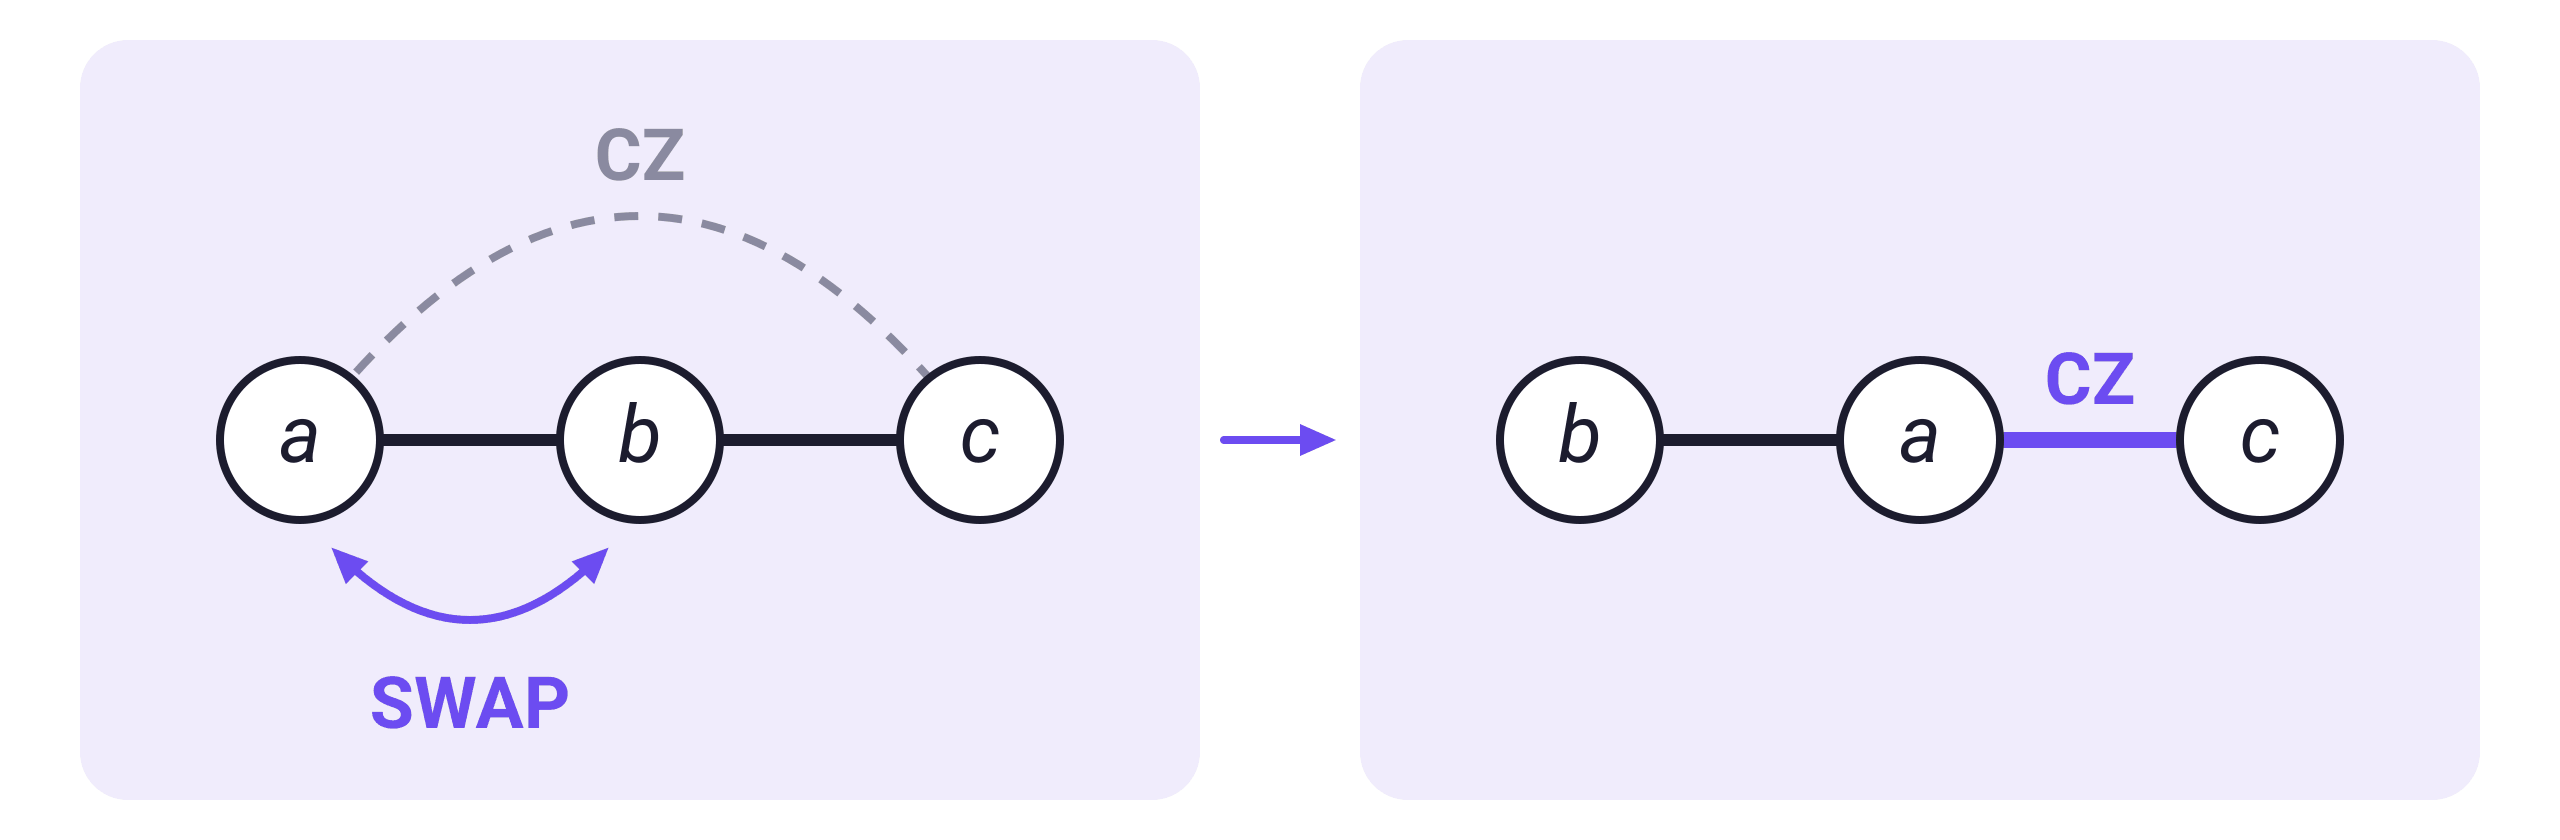

In [ ]:
from collections import Counter
from qilisdk.digital.circuit_transpiler import CircuitTranspiler, SingleQubitGateBasis, TwoQubitGateBasis

# The chip's couplers
line = [(0, 1), (1, 2), (2, 3)]

# U3 is one general single-qubit gate; CZ is the only two-qubit gate
transpiler = CircuitTranspiler.default(
    single_qubit_basis=SingleQubitGateBasis.U3,
    two_qubit_basis=TwoQubitGateBasis.CZ,
    topology=line,
)
line_result = transpiler.transpile(qft)

# Gate counts before and after compiling, then the SWAPs the router inserted
print(Counter(gate.name for gate in qft.gates))
print(Counter(gate.name for gate in line_result.circuit.gates))
print(line_result.metrics)

# The qubit pairs the CZ gates act on: all of them are couplers
print({gate.qubits for gate in line_result.circuit.gates if gate.name == "CZ"})

# The compiler passes, in order
for step in line_result.intermediate_results:
    print(step.name)

Compare the gate counts before and after compilation. The logical circuit contains 10 gates: 4 `H` gates and 6 controlled phase gates, printed as `CU1`. The compiled circuit uses only `U3` and `CZ`. Your counts may differ between runs because SABRE makes random choices. In repeated compilations with QiliSDK 0.3.0, the line needed 3, 4, or 5 SWAPs, which means 21, 24, or 27 `CZ` gates. The total was 57 to 77 gates, about six to eight times the logical count.

In this decomposition the six controlled phases need 12 `CZ` gates, and each SWAP adds three more. The printed set of `CZ` pairs shows that every compiled two-qubit gate acts on a pair in the coupling map. The printed pass list reads top to bottom: split gates with several controls (none here), cancel adjacent gate pairs that undo each other, decompose to the chosen basis, fuse neighboring single-qubit gates, let SABRE choose a layout and insert SWAPs, then decompose and fuse once more so the new SWAPs also become `CZ` and `U3` gates.

Extra gates matter because qubits are fragile. Stray interactions with their surroundings gradually scramble a qubit's amplitudes and phases. This is called **decoherence**. Superconducting qubits keep their state for roughly 0.1 to 1 ms. Trapped ions keep it for seconds, but their gates are much slower. What counts is how many gates fit in that time. The gates themselves are imperfect too: good two-qubit gates fail about once in a few hundred to a few thousand operations.

To estimate the effect of extra gates, let $p$ be the error probability of each two-qubit gate and $G$ the number of those gates. Under a model of independent gate failures, each gate succeeds with probability $1-p$, so the probability that all succeed is roughly $(1-p)^G$. With $p = 0.5\%$, 12 two-qubit gates all succeed with probability about 0.94, and 24 gates about 0.89. This is an illustrative error model, not a prediction of a device's measured accuracy.

On the line, routing can roughly double the two-qubit count from the 12 required by this decomposition. Exercise 2.2's CNOT chain, by comparison, uses neighboring qubits and fits on the line without SWAPs. Gate quality and connectivity therefore matter alongside the number of qubits.

### 🧩 Exercise 2.3: evaluate a chip upgrade

Your team can afford **one hardware upgrade** for the four-qubit line chip. An extra coupler between qubits 3 and 0 would turn it into a **ring**. Use the compiler to estimate the benefit for the QFT before deciding whether the extra connection is worth its cost.

Transpile the same `qft` using the same native gates and the ring topology. Compare its native **two-qubit gate count**, the number of `CZ` gates, with the line's from the preceding example. Each SWAP saved removes three two-qubit gates from the illustrative $(1-p)^G$ error model, but the benefit depends on the circuit and the routing result.

- Change only the transpiler's `topology=` argument.
- Print the pairs the `CZ` gates act on, as the demo does, and check that each one is a ring coupler.
- Repeat both compilations a few times because SABRE is stochastic.
- Report the gate-count comparison and explain what it tells you about the extra coupler. State what additional cost and error-rate information you would need to compare it with faster gates, which let more gates fit before the qubits decohere.

In the figure below, solid lines are couplers, dashed lines are pairs the QFT needs but the chip lacks, and the new 3–0 coupler is highlighted.

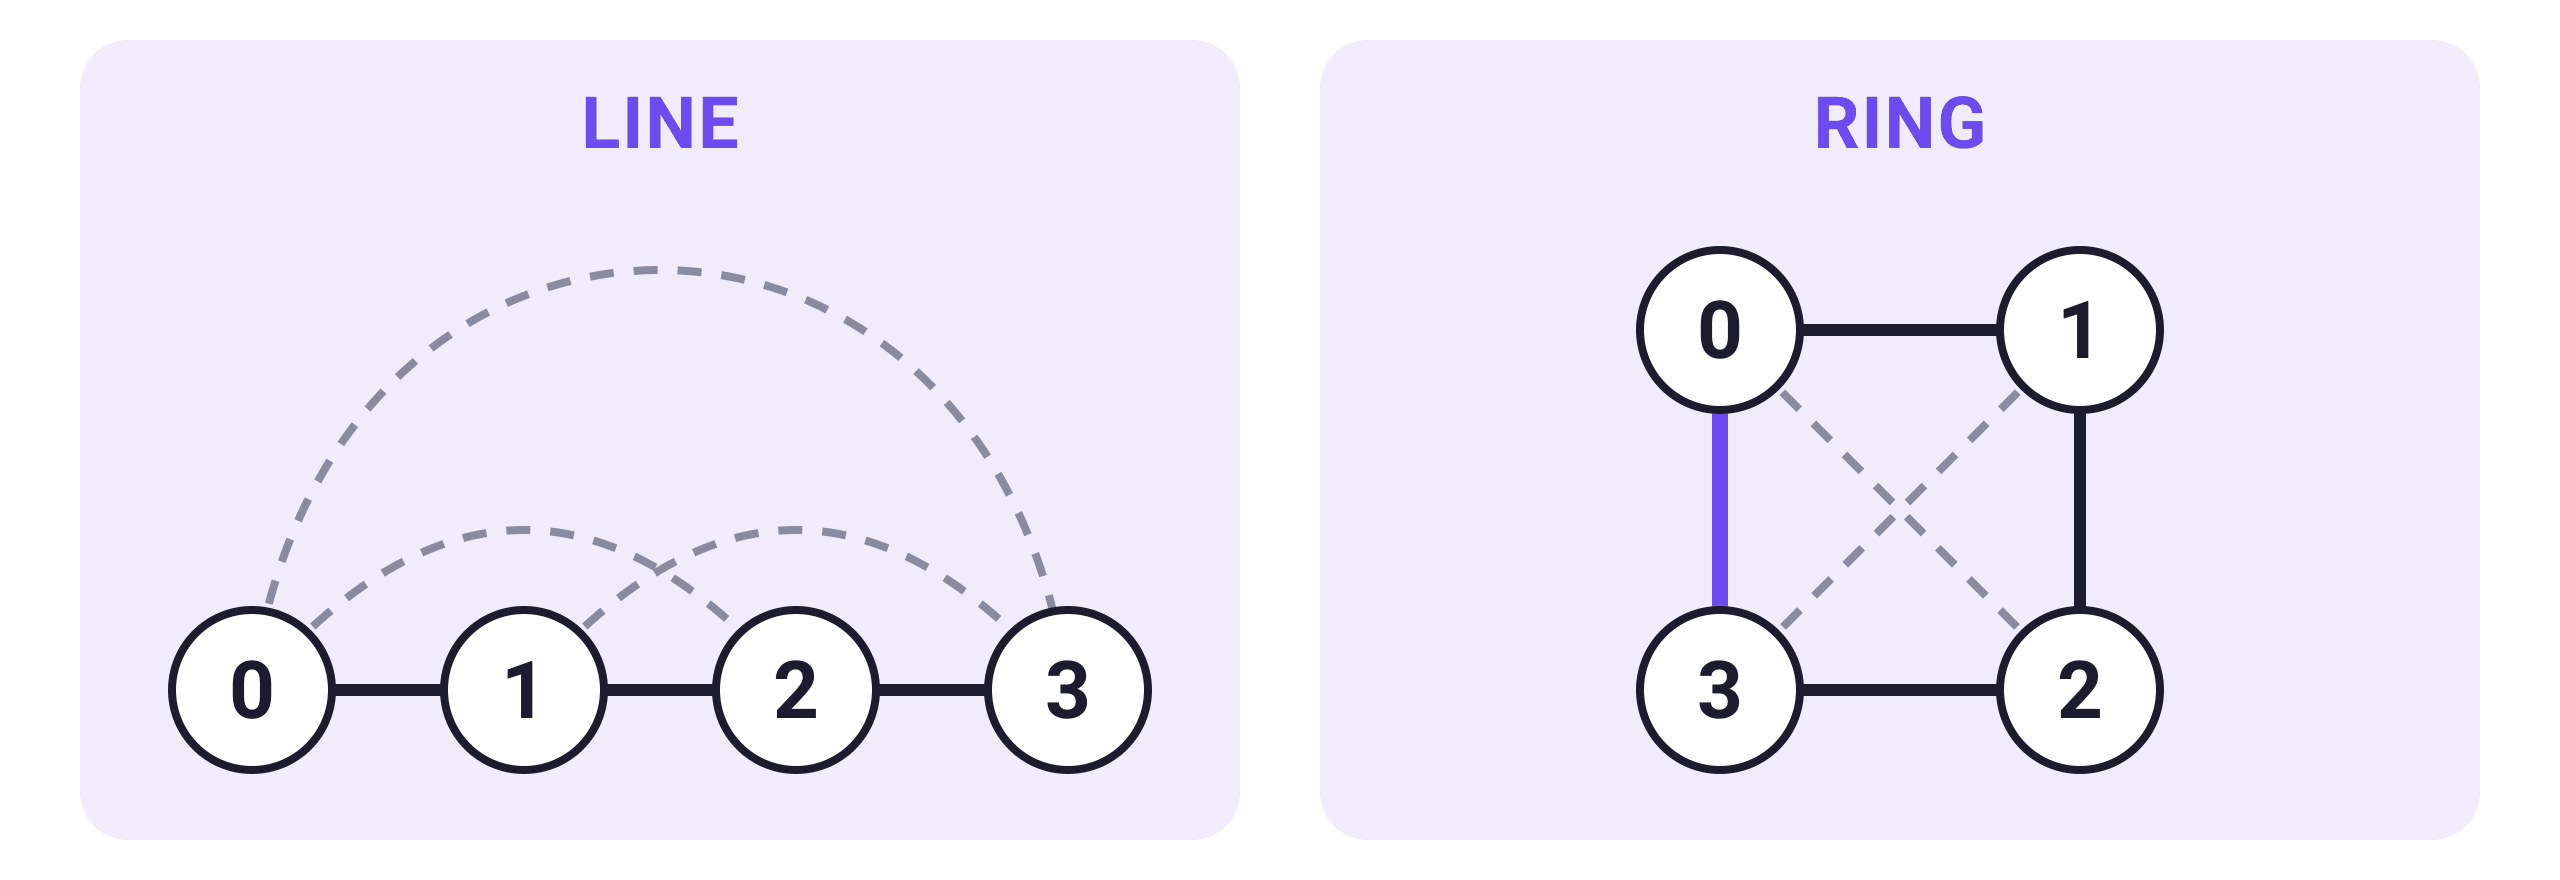

In [ ]:
# Add a coupler between the ends of the line
ring = [(0, 1), (1, 2), (2, 3), (3, 0)]

# TODO: build a CircuitTranspiler.default(...) with the same native gates as the demo but
#       topology=ring, transpile `qft`, and print the compiled gate counts, the metrics,
#       and the pairs the CZ gates act on.
# TODO (answer in a comment): what does the CZ count tell you compared with the line, and
#       what cost and error-rate data would you need to compare a coupler with faster gates?


## Recap and what's next

Gates act as unitary matrices, and a `Circuit` applies them in the order added: applying $A$ and then $B$ computes $B\,A\,|\psi\rangle$. The Pauli-$X$ gate flips $|0\rangle$ and $|1\rangle$, Pauli-$Z$ exchanges $|+\rangle$ and $|-\rangle$, and Hadamard changes between these two bases. Each gate's matrix is available through `.matrix`.

The two-Hadamard example shows how interference cancels an amplitude before measurement. Bell and GHZ circuits show how gates prepare entangled states whose measured bits agree; the Bell pair agrees in the $X$ basis too, which a copied classical coin cannot do.

`Backend.execute(functional, readout)` runs a circuit wrapped in `DigitalPropagation`. On `QiliSim`, sampling gives estimated probabilities whose statistical uncertainty shrinks as $1/\sqrt{\text{nshots}}$. The state-tomography readout provides probabilities from the stored state without shot noise. You used both readouts to check the coin, dice, and shared-bit examples.

The transpiler converted the 10-gate QFT into native `U3` and `CZ` gates and used SABRE to route two-qubit interactions onto physical couplers. Comparing the line and ring layouts shows how connectivity affects the number of operations needed for a particular circuit. Every extra gate is another chance for an error and adds time in which the qubits decohere. That is why the count matters.

### Where to go next

The [3-hour version of this tutorial](https://github.com/qilimanjaro-tech/europython2026-qilisdk-tutorial), first given at EuroPython 2026, continues with four notebooks: **analog computing**, using energy operators called Hamiltonians and annealing schedules; **variational algorithms**, including the variational quantum eigensolver (VQE) for the hydrogen molecule and the quantum approximate optimization algorithm (QAOA); **noise** and realistic execution; and **execution** on other backends and hardware.

- **Documentation** (English, Spanish, and Catalan): <https://qilimanjaro-tech.github.io/qilisdk/>
- **Source:** <https://github.com/qilimanjaro-tech/qilisdk>
- **Diagnostics:** `print(qilisdk.about())` reports your QiliSDK and Python versions, whether the optional QuTiP and CUDA-Q packages are installed, and your CPU and GPU.